<a href="https://colab.research.google.com/github/srija-112/student-performance-prediction/blob/main/student_performance_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("Student Performance Prediction")
print("Linear Regression Project")

Student Performance Prediction
Linear Regression Project


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

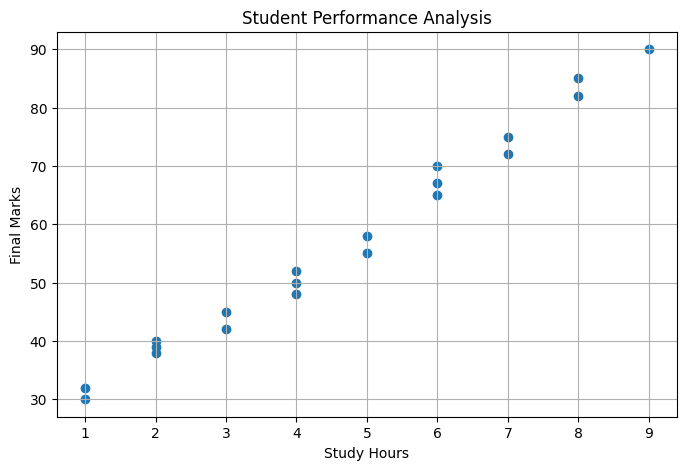

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Study_Hours"],
    df["Final_Marks"]
)

plt.xlabel("Study Hours")
plt.ylabel("Final Marks")

plt.title("Student Performance Analysis")

plt.grid(True)
plt.show()

In [ ]:
# Input features
X = df[["Study_Hours", "Previous_Marks"]]

# Target variable
y = df["Final_Marks"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [ ]:
# Predict marks for test data
y_pred = model.predict(X_test)

# Calculate model performance
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Actual Marks:", list(y_test))
print("Predicted Marks:", np.round(y_pred, 2))
print("Mean Absolute Error:", round(mae, 2))
print("R2 Score:", round(r2, 2))

Actual Marks: [32, 52, 30, 38]
Predicted Marks: [31.16 50.58 29.44 37.06]
Mean Absolute Error: 0.94
R2 Score: 0.99


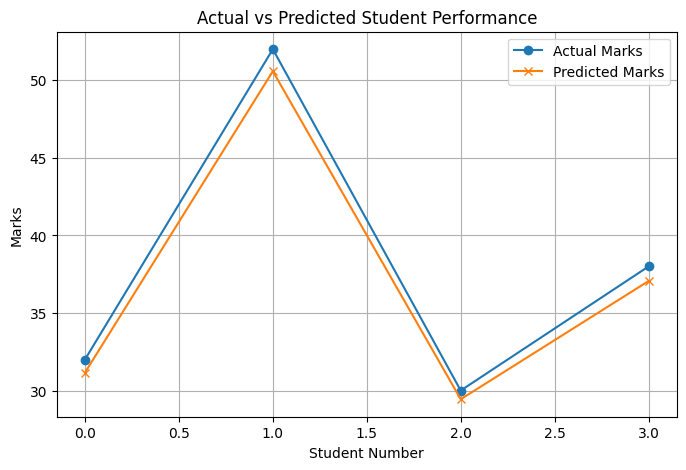

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(len(y_test)),
    list(y_test),
    marker="o",
    label="Actual Marks"
)

plt.plot(
    range(len(y_pred)),
    y_pred,
    marker="x",
    label="Predicted Marks"
)

plt.xlabel("Student Number")
plt.ylabel("Marks")

plt.title("Actual vs Predicted Student Performance")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from IPython.display import display, HTML, clear_output
import ipywidgets as widgets
import pandas as pd

# Purple Theme
display(HTML("""
<style>
.purple-card {
    background: linear-gradient(135deg, #f3e8ff, #e9d5ff);
    border: 2px solid #a855f7;
    border-radius: 18px;
    padding: 22px;
    text-align: center;
    margin-bottom: 18px;
}
.purple-card h1 {
    color: #6b21a8;
    margin-bottom: 8px;
}
.purple-card p {
    color: #581c87;
    font-size: 15px;
}
</style>
<div class="purple-card">
    <h1>🎓 Student Performance Prediction</h1>
    <p>Machine Learning Based Marks Prediction System</p>
</div>
"""))

# Student inputs
student_name = widgets.Text(
    description="Name:",
    placeholder="Enter student name",
    layout=widgets.Layout(width="350px")
)

study_hours = widgets.FloatText(
    description="Study Hours:",
    value=5,
    layout=widgets.Layout(width="350px")
)

previous_marks = widgets.FloatText(
    description="Previous Marks:",
    value=60,
    layout=widgets.Layout(width="350px")
)

# Purple button
predict_button = widgets.Button(
    description="Predict Performance",
    layout=widgets.Layout(width="250px", height="42px"),
    style=widgets.ButtonStyle(
        button_color="#9333ea",
        font_weight="bold"
    )
)

output = widgets.Output()

def predict_performance(button):
    with output:
        clear_output()

        name = student_name.value.strip()
        hours = study_hours.value
        marks = previous_marks.value

        if not name:
            print("Please enter student name.")
            return

        if hours < 0 or marks < 0 or marks > 100:
            print("Please enter valid values.")
            return

        new_student = pd.DataFrame({
            "Study_Hours": [hours],
            "Previous_Marks": [marks]
        })

        prediction = model.predict(new_student)[0]
        prediction = max(0, min(100, prediction))

        display(HTML(f"""
        <div style="
            background:#f3e8ff;
            border:2px solid #9333ea;
            border-radius:15px;
            padding:20px;
            color:#581c87;
            margin-top:15px;">
            <h2>📊 Student Performance Report</h2>
            <p><b>Student Name:</b> {name}</p>
            <p><b>Study Hours:</b> {hours}</p>
            <p><b>Previous Marks:</b> {marks}</p>
            <h2>Predicted Final Marks: {prediction:.2f}</h2>
            <p><i>Prediction based on sample training data.</i></p>
        </div>
        """))

predict_button.on_click(predict_performance)

display(
    student_name,
    study_hours,
    previous_marks,
    predict_button,
    output
)

Text(value='', description='Name:', layout=Layout(width='350px'), placeholder='Enter student name')

FloatText(value=5.0, description='Study Hours:', layout=Layout(width='350px'))

FloatText(value=60.0, description='Previous Marks:', layout=Layout(width='350px'))

Button(description='Predict Performance', layout=Layout(height='42px', width='250px'), style=ButtonStyle(butto…

Output()

In [ ]:
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 2, 3,
                    4, 5, 6, 7, 8, 1, 2, 4, 6, 9],

    "Previous_Marks": [30, 35, 40, 45, 50, 60, 65, 75, 38, 42,
                       48, 55, 62, 70, 80, 28, 36, 47, 64, 85],

    "Final_Marks": [32, 38, 42, 48, 55, 65, 72, 82, 40, 45,
                    50, 58, 67, 75, 85, 30, 39, 52, 70, 90]
}

df = pd.DataFrame(data)

print(df)

    Study_Hours  Previous_Marks  Final_Marks
0             1              30           32
1             2              35           38
2             3              40           42
3             4              45           48
4             5              50           55
5             6              60           65
6             7              65           72
7             8              75           82
8             2              38           40
9             3              42           45
10            4              48           50
11            5              55           58
12            6              62           67
13            7              70           75
14            8              80           85
15            1              28           30
16            2              36           39
17            4              47           52
18            6              64           70
19            9              85           90
